<center><h1> <font color='blue'> 

**Proyecto Censo 2024**

Notebook 02: Exploración y análisis de asociaciones

</font></h1></center>


<font color=green>

# **Escolaridad y condiciones de vida en Chile**

</font>

### **Análisis de los microdatos del Censo 2024**

**Autor:** Nelson Hernández Becerra  
**Fecha:** octubre 2026  
**Herramientas:** Python, DuckDB, pandas

### **Introducción**

El nivel educativo es uno de los factores más estudiados en las ciencias sociales por su relación con el empleo, la vivienda y el acceso a servicios. Este proyecto explora cómo se asocian los años de escolaridad de las personas en Chile con distintos aspectos de su vida cotidiana, usando los microdatos del Censo de Población y Vivienda 2024 del INE.

### **Pregunta de investigación**
¿Cómo se asocia el nivel de escolaridad de las personas con sus condiciones de vida (trabajo, vivienda, acceso a internet), una vez controlados factores como la edad y el sexo?

### **Objetivos**
1. Cargar, validar y documentar los microdatos censales.
2. Describir la distribución de la escolaridad en la población.
3. Analizar su asociación con variables de vida diaria.
4. Comunicar los resultados y sus limitaciones de forma clara.

### **Datos**
Este análisis usa la base construida en el notebook `01_preparacion_datos`: 12.427.678 personas de 25 años o más que residen en viviendas particulares, con los datos de su hogar y su vivienda. Las decisiones sobre el universo y el tratamiento de los datos están justificadas en ese notebook.

<font color=blue>

## 🔵 **1. Carga de la base**

</font>

Se carga la base analítica guardada en formato Parquet y se verifica que contenga lo esperado: 12.427.678 filas y 24 columnas.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUTA_BASE = Path("../data/processed/base_analitica_censo2024.parquet")
print("Archivo:", "OK" if RUTA_BASE.exists() else "NO ENCONTRADO")

con = duckdb.connect()
con.execute(f"""
    CREATE OR REPLACE VIEW base AS
    SELECT * FROM read_parquet('{RUTA_BASE.as_posix()}')
""")

con.execute("SELECT COUNT(*) AS filas FROM base").df()

Archivo: OK


,filas
0,12427678


> La base se cargó correctamente: el archivo existe y contiene **12.427.678 filas**, igual que el universo definido en el notebook 01.

<font color =blue>

## 🔵 **2. Exploración de la escolaridad**

</font>

En esta sección se describe la distribución de los años de escolaridad en la base analítica, primero en el conjunto de la población y luego según sexo, edad y región.

<font color=green>

### 🟢 **2.1 Estadísticos descriptivos**

</font>

Se calculan el promedio, la mediana, los cuartiles y el rango de los años de escolaridad. Comparar el promedio con la mediana permite evaluar si la distribución es simétrica o está sesgada hacia valores altos o bajos.

In [2]:
con.execute("""
    SELECT
        COUNT(*) AS n,
        ROUND(AVG(escolaridad), 2) AS promedio,
        MEDIAN(escolaridad) AS mediana,
        QUANTILE_CONT(escolaridad, 0.25) AS p25,
        QUANTILE_CONT(escolaridad, 0.75) AS p75,
        MIN(escolaridad) AS minimo,
        MAX(escolaridad) AS maximo
    FROM base
""").df()

,n,promedio,mediana,p25,p75,minimo,maximo
0,12427678,12.06,12.0,10.0,15.0,0,24


> En la base analítica (12.427.678 personas) la escolaridad promedio es de **12,06 años** y la mediana de **12 años**. El 50 % central se ubica entre 10 años (percentil 25) y 15 años (percentil 75), con un rango de 0 a 24 años.

La cercanía entre el promedio y la mediana indica una distribución aproximadamente simétrica, con la persona típica en enseñanza media completa (12 años). La dispersión es algo mayor hacia valores altos (la mediana está 2 años sobre el percentil 25 y 3 años bajo el percentil 75).

<font color=green>

### 🟢 **2.2 Escolaridad según sexo**

</font>

Se comparan hombres y mujeres en cantidad de personas, escolaridad promedio y mediana, proporción con estudios superiores y edad promedio. Esta última se incluye porque la edad se asocia con la escolaridad: una diferencia de edad entre ambos grupos podría explicar parte de la diferencia observada.

In [3]:
con.execute("""
    SELECT
        CASE sexo WHEN 1 THEN 'Hombre' WHEN 2 THEN 'Mujer' END AS sexo,
        COUNT(*) AS n,
        ROUND(AVG(escolaridad), 2) AS prom_escolaridad,
        MEDIAN(escolaridad) AS mediana,
        ROUND(100.0 * AVG(CASE WHEN nivel_educ = '4. Superior' THEN 1 ELSE 0 END), 1) AS pct_superior,
        ROUND(AVG(edad), 1) AS prom_edad
    FROM base
    GROUP BY sexo
    ORDER BY sexo
""").df()

,sexo,n,prom_escolaridad,mediana,pct_superior,prom_edad
0,Hombre,5858650,12.11,12.0,39.0,48.7
1,Mujer,6569028,12.01,12.0,40.3,50.2


> La base está compuesta por 5.858.650 hombres (47,1 %) y 6.569.028 mujeres (52,9 %). La escolaridad promedio es de 12,11 años en hombres y 12,01 en mujeres (diferencia de 0,10 años), con la misma mediana (12 años). Un 40,3 % de las mujeres y un 39,0 % de los hombres tiene estudios superiores. La edad promedio es de 48,7 años en hombres y 50,2 en mujeres.

La diferencia en el promedio de escolaridad entre sexos es muy pequeña, y la proporción con estudios superiores es levemente mayor en mujeres. Las mujeres son en promedio 1,5 años mayores, lo que podría explicar parte de su menor promedio, dado que la edad se asocia negativamente con la escolaridad. Esto se evaluará comparando hombres y mujeres dentro de cada tramo de edad.

<font color=green>

### 🟢 **2.3 Escolaridad por sexo dentro de cada tramo de edad**

</font>

Para evaluar si la diferencia entre sexos se debe a la distinta composición por edad, se comparan hombres y mujeres dentro de cada tramo de edad. Esta estratificación permite contrastar personas de edades similares.

In [4]:
con.execute("""
    SELECT
        tramo_edad,
        ROUND(AVG(CASE WHEN sexo = 1 THEN escolaridad END), 2) AS prom_hombres,
        ROUND(AVG(CASE WHEN sexo = 2 THEN escolaridad END), 2) AS prom_mujeres,
        ROUND(AVG(CASE WHEN sexo = 2 THEN escolaridad END)
              - AVG(CASE WHEN sexo = 1 THEN escolaridad END), 2) AS dif_mujeres_menos_hombres
    FROM base
    GROUP BY tramo_edad
    ORDER BY tramo_edad
""").df()

,tramo_edad,prom_hombres,prom_mujeres,dif_mujeres_menos_hombres
0,25-34,13.65,14.20,0.56
1,35-44,13.43,13.71,0.28
2,45-54,12.34,12.38,0.04
3,55-64,10.97,10.85,-0.12
4,65-74,10.12,9.72,-0.40
5,75-84,8.63,7.96,-0.67
6,85+,7.53,6.87,-0.66


> La diferencia de escolaridad entre mujeres y hombres cambia de signo según la edad. En los tramos de 25-34 y 35-44 años las mujeres tienen más escolaridad (+0,56 y +0,28 años), en el de 45-54 la diferencia es prácticamente nula (+0,04), y desde los 55 años los hombres tienen más escolaridad, con una brecha que llega a 0,67 años en el tramo de 75-84.

La pequeña diferencia observada en el conjunto (2.2) resulta de efectos opuestos según la edad, y de la mayor presencia de mujeres en las edades más avanzadas. Un patrón compatible con estos resultados es que las generaciones más jóvenes de mujeres accedieron a la educación en mayor medida que las anteriores; con datos de un único momento no es posible separar el efecto de la generación del de la edad. Las diferencias menores a 0,1 años se consideran prácticamente nulas.

> **Consecuencia para el análisis:** el sexo y la edad deben considerarse conjuntamente al comparar escolaridad, no por separado.

<font color=green>

### 🟢 **2.4 Escolaridad por región**

</font>

Se compara la escolaridad promedio entre las 16 regiones del país, junto con la proporción de personas con estudios superiores y la edad promedio de cada región. Esta última se incluye porque las diferencias de edad entre regiones podrían explicar parte de las diferencias de escolaridad.

In [5]:
con.execute("""
    SELECT
        CASE region
            WHEN 1 THEN 'Tarapacá'
            WHEN 2 THEN 'Antofagasta'
            WHEN 3 THEN 'Atacama'
            WHEN 4 THEN 'Coquimbo'
            WHEN 5 THEN 'Valparaíso'
            WHEN 6 THEN 'O''Higgins'
            WHEN 7 THEN 'Maule'
            WHEN 8 THEN 'Biobío'
            WHEN 9 THEN 'La Araucanía'
            WHEN 10 THEN 'Los Lagos'
            WHEN 11 THEN 'Aysén'
            WHEN 12 THEN 'Magallanes'
            WHEN 13 THEN 'Metropolitana'
            WHEN 14 THEN 'Los Ríos'
            WHEN 15 THEN 'Arica y Parinacota'
            WHEN 16 THEN 'Ñuble'
        END AS nombre_region,
        COUNT(*) AS n,
        ROUND(AVG(escolaridad), 2) AS prom_escolaridad,
        ROUND(100.0 * AVG(CASE WHEN nivel_educ = '4. Superior' THEN 1 ELSE 0 END), 1) AS pct_superior,
        ROUND(AVG(edad), 1) AS prom_edad
    FROM base
    GROUP BY region
    ORDER BY prom_escolaridad DESC
""").df()

,nombre_region,n,prom_escolaridad,pct_superior,prom_edad
0,Metropolitana,5035778,12.71,46.0,48.7
1,Antofagasta,406784,12.46,39.8,46.6
2,Magallanes,113797,12.33,42.8,49.6
3,Arica y Parinacota,153976,12.29,39.6,48.8
4,Tarapacá,225527,12.28,36.7,46.5
5,Valparaíso,1301010,12.27,41.2,50.8
6,Aysén,54118,11.80,39.9,48.7
7,Biobío,1085077,11.79,38.3,50.2
8,Atacama,192650,11.74,34.0,48.8
9,Coquimbo,548122,11.74,35.8,49.8


> La escolaridad promedio varía entre 10,9 años (Maule) y 12,7 años (Región Metropolitana), una diferencia cercana a 1,8 años. Las regiones se agrupan en tres bloques: Metropolitana, Antofagasta, Magallanes, Arica y Parinacota, Tarapacá y Valparaíso (12,3 a 12,7 años); Aysén, Biobío, Atacama y Coquimbo (11,7 a 11,8); y Los Ríos, O'Higgins, Los Lagos, La Araucanía, Ñuble y Maule (10,9 a 11,3). La Región Metropolitana también presenta la mayor proporción de personas con estudios superiores (46,0 %).

Las regiones con población más envejecida tienden a tener menor escolaridad (por ejemplo, Ñuble y Maule), pero la edad no explica todas las diferencias: Valparaíso tiene una de las edades promedio más altas (50,8 años) y aun así una escolaridad elevada (12,3). Es posible que intervengan otros factores, como la proporción de población rural, que la base actual no incluye.

Queda pendiente evaluar la incorporación de la variable de zona (urbana o rural) a la base analítica, para usarla como control en el análisis.

<font color=green>

### 🟢 **2.5 Escolaridad promedio por edad y sexo**

</font>

Se grafica la escolaridad promedio para cada edad, separando hombres y mujeres, para visualizar la relación entre edad y escolaridad y el cambio en la diferencia entre sexos observado en 2.3. La edad 85 agrupa a todas las personas de 85 años o más.

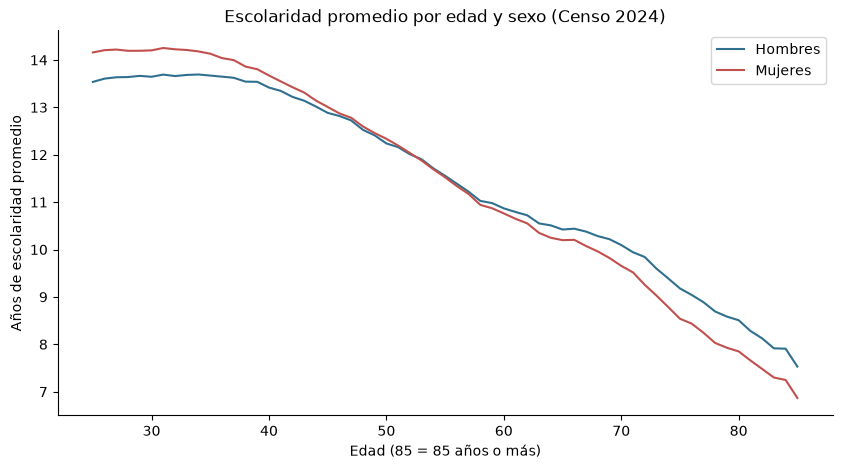

In [6]:
df_edad = con.execute("""
    SELECT edad, sexo, AVG(escolaridad) AS prom_escolaridad
    FROM base
    GROUP BY edad, sexo
    ORDER BY edad, sexo
""").df()

tabla = df_edad.pivot(index="edad", columns="sexo", values="prom_escolaridad")
tabla.columns = ["Hombres", "Mujeres"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tabla.index, tabla["Hombres"], label="Hombres", color="#2f6f8f")
ax.plot(tabla.index, tabla["Mujeres"], label="Mujeres", color="#c0504d")
ax.set_title("Escolaridad promedio por edad y sexo (Censo 2024)")
ax.set_xlabel("Edad (85 = 85 años o más)")
ax.set_ylabel("Años de escolaridad promedio")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

> La escolaridad promedio es estable entre los 25 y los 37 años aproximadamente (cerca de 13,6 años en hombres y 14,2 en mujeres) y desciende de forma sostenida desde los 40 años, con mayor pendiente a partir de los 50, hasta alrededor de 7,5 años en hombres y 6,9 en mujeres en el grupo de 85 años o más. Las curvas de ambos sexos se cruzan en torno a los 52-53 años: antes de esa edad las mujeres tienen mayor escolaridad promedio, y después los hombres.

El patrón es coherente con el efecto generacional observado en 2.3: en las cohortes más jóvenes las mujeres superan a los hombres, mientras que en las mayores ocurre lo contrario. La meseta entre los 25 y los 37 años sugiere que el acceso a la educación se ha estabilizado en las generaciones recientes. El último punto (85) corresponde a un grupo abierto ("85 años o más") y no a una edad exacta.

<font color=green>

### 🟢 **2.6 Resumen de la exploración**

</font>

- La persona típica de la base (25 años o más, vivienda particular) tiene enseñanza media completa: promedio de 12,06 años y mediana de 12.
- Entre hombres y mujeres la diferencia global es mínima (0,10 años), pero oculta un cruce según la edad: las mujeres tienen más escolaridad en las generaciones jóvenes y los hombres en las mayores, con el punto de cruce cerca de los 52-53 años.
- La edad es el factor con más peso: la escolaridad promedio cae de unos 14 años en los 25-34 a cerca de 7 en los 85 o más.
- Entre regiones hay una brecha de unos 1,8 años (de 10,9 en Maule a 12,7 en la Región Metropolitana), que la edad explica solo en parte.
- **Implicancia:** al estudiar la asociación entre escolaridad y condiciones de vida, será necesario controlar al menos por edad y sexo, y probablemente por región.

<font color= blue>

## 🔵 **3. Escolaridad y condiciones de vida**

</font>

En esta sección se examina cómo se asocia el nivel educativo con tres dimensiones de la vida cotidiana: el trabajo, la vivienda y el acceso a internet. En cada caso se comienza con una comparación simple y luego se controla por edad.

<font color=green>

### 🟢 **3.1 Situación laboral según nivel educativo**

</font>

Se calcula, para cada nivel educativo, el porcentaje de personas ocupadas, desocupadas y fuera de la fuerza de trabajo, excluyendo los registros sin respuesta. Se incluye la edad promedio de cada nivel para evaluar si las diferencias podrían reflejar la edad y no la escolaridad.

In [7]:
con.execute("""
    SELECT
        nivel_educ,
        COUNT(*) AS n,
        ROUND(100.0 * AVG(CASE WHEN sit_fuerza_trabajo = 1 THEN 1 ELSE 0 END), 1) AS pct_ocupados,
        ROUND(100.0 * AVG(CASE WHEN sit_fuerza_trabajo = 2 THEN 1 ELSE 0 END), 1) AS pct_desocupados,
        ROUND(100.0 * AVG(CASE WHEN sit_fuerza_trabajo = 3 THEN 1 ELSE 0 END), 1) AS pct_fuera,
        ROUND(AVG(edad), 1) AS prom_edad
    FROM base
    WHERE sit_fuerza_trabajo IN (1, 2, 3)
    GROUP BY nivel_educ
    ORDER BY nivel_educ
""").df()

,nivel_educ,n,pct_ocupados,pct_desocupados,pct_fuera,prom_edad
0,1. Básica o menos,2630105,35.2,3.5,61.3,62.0
1,2. Media incompleta,1219564,50.9,5.3,43.8,54.4
2,3. Media completa,3643925,63.3,6.1,30.6,47.1
3,4. Superior,4930240,75.7,5.1,19.2,43.3


> El porcentaje de personas ocupadas aumenta con el nivel educativo, desde 35,2 % en básica o menos hasta 75,7 % en superior, mientras que el porcentaje fuera de la fuerza de trabajo disminuye de 61,3 % a 19,2 %. El porcentaje de desocupados sobre el total del grupo varía poco entre niveles (3,5 % a 6,1 %).

La edad promedio también difiere considerablemente entre niveles (62,0 años en básica o menos frente a 43,3 en superior), y las personas mayores están con más frecuencia fuera de la fuerza de trabajo (por ejemplo, por jubilación). Por esta razón, estas diferencias no pueden atribuirse a la escolaridad sin controlar por edad (3.2). Además, el porcentaje de desocupados se calcula sobre el total de personas del grupo y no sobre la fuerza de trabajo, por lo que no equivale a la tasa de desocupación.

<font color=green>

### 🟢 **3.2 Tasa de ocupación por nivel educativo y tramo de edad**

</font>

Para evaluar si la asociación observada en 3.1 se debe a diferencias de edad, se calcula la tasa de ocupación (porcentaje de personas ocupadas) de cada nivel educativo dentro de cada tramo de edad. Si la diferencia entre niveles persiste al comparar personas de edades similares, la edad no explica por sí sola la asociación.

In [8]:
con.execute("""
    SELECT
        tramo_edad,
        ROUND(100.0 * AVG(CASE WHEN sit_fuerza_trabajo = 1 THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '1. Básica o menos'), 1) AS basica_o_menos,
        ROUND(100.0 * AVG(CASE WHEN sit_fuerza_trabajo = 1 THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '2. Media incompleta'), 1) AS media_incompleta,
        ROUND(100.0 * AVG(CASE WHEN sit_fuerza_trabajo = 1 THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '3. Media completa'), 1) AS media_completa,
        ROUND(100.0 * AVG(CASE WHEN sit_fuerza_trabajo = 1 THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '4. Superior'), 1) AS superior
    FROM base
    WHERE sit_fuerza_trabajo IN (1, 2, 3)
    GROUP BY tramo_edad
    ORDER BY tramo_edad
""").df()

,tramo_edad,basica_o_menos,media_incompleta,media_completa,superior
0,25-34,53.8,65.8,71.3,78.6
1,35-44,58.7,69.1,73.3,86.1
2,45-54,58.6,66.8,71.6,83.2
3,55-64,50.0,56.9,61.8,72.2
4,65-74,20.6,25.0,26.9,33.6
5,75-84,6.3,8.0,8.4,13.8
6,85+,1.3,2.0,2.1,5.0


> Dentro de cada tramo de edad, la tasa de ocupación aumenta con el nivel educativo, sin excepciones. Entre los 25 y los 64 años, la diferencia entre el nivel más bajo y el más alto es de 22 a 27 puntos porcentuales (por ejemplo, en el tramo 35-44: 58,7 % en básica o menos y 86,1 % en superior). Desde los 65 años la ocupación cae para todos los niveles y las diferencias se reducen (13,0 puntos en 65-74 y 3,7 en el grupo de 85 años o más).

Al comparar personas de edades similares, la brecha de ocupación entre niveles educativos se reduce respecto de la observada en 3.1 (de unos 40 puntos a unos 25), por lo que aproximadamente un tercio de esa brecha se explicaba por la edad. La asociación, sin embargo, persiste.

Los tramos de diez años aún agrupan edades distintas, y no se ha controlado por sexo ni por región. Estos resultados describen una asociación y no permiten afirmar que la escolaridad cause una mayor ocupación.

### <font color=green> 🟢 **3.3 Gráfico: tasa de ocupación por edad y nivel educativo**</font>

Se visualiza el resultado de 3.2: una línea por nivel educativo, con la tasa de ocupación en cada tramo de edad.

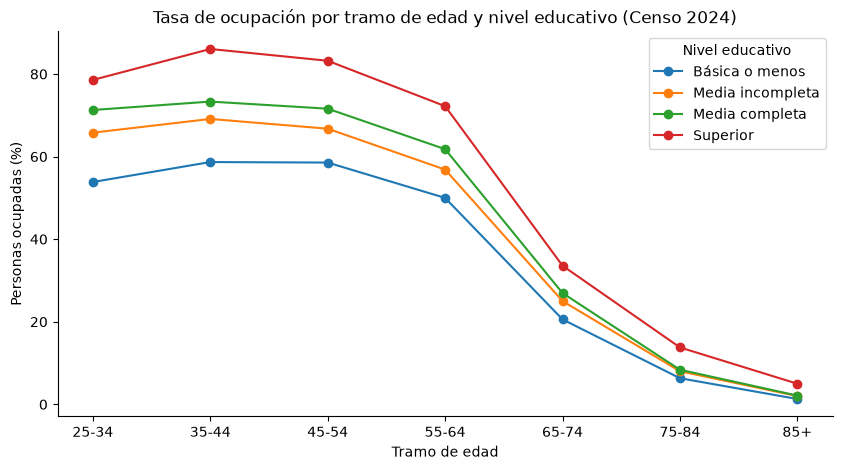

In [9]:
ocup = con.execute("""
    SELECT
        tramo_edad,
        nivel_educ,
        100.0 * AVG(CASE WHEN sit_fuerza_trabajo = 1 THEN 1.0 ELSE 0.0 END) AS tasa_ocupacion
    FROM base
    WHERE sit_fuerza_trabajo IN (1, 2, 3)
    GROUP BY tramo_edad, nivel_educ
    ORDER BY tramo_edad, nivel_educ
""").df()

tabla = ocup.pivot(index="tramo_edad", columns="nivel_educ", values="tasa_ocupacion")

fig, ax = plt.subplots(figsize=(10, 5))
for nivel in tabla.columns:
    ax.plot(tabla.index, tabla[nivel], marker="o", label=nivel[3:])

ax.set_title("Tasa de ocupación por tramo de edad y nivel educativo (Censo 2024)")
ax.set_xlabel("Tramo de edad")
ax.set_ylabel("Personas ocupadas (%)")
ax.legend(title="Nivel educativo")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

> En todos los tramos de edad la tasa de ocupación aumenta con el nivel educativo, sin que las curvas se crucen. La separación entre niveles es máxima entre los 35 y los 54 años (25 a 27 puntos entre superior y básica o menos) y se reduce desde los 65 años, cuando la ocupación cae para todos. Desde esa edad, los niveles de media incompleta y media completa son prácticamente indistinguibles.

La asociación positiva entre escolaridad y ocupación se mantiene al comparar personas de edades similares, aunque más débil que en la comparación sin controles (3.1). Los resultados describen una asociación y no una relación causal.

### 🟢 <font color=green> **3.4 Hacinamiento según nivel educativo y edad** </font>

Se calcula el porcentaje de personas que viven en hogares con hacinamiento (medio o crítico) para cada nivel educativo, dentro de cada tramo de edad, y para el conjunto de la población (fila "Total"). El hacinamiento es una característica de la vivienda, por lo que todos los integrantes de un hogar comparten el mismo valor. Se excluyen los registros sin dato.

In [10]:
con.execute("""
    SELECT
        COALESCE(tramo_edad, 'Total') AS tramo_edad,
        ROUND(100.0 * AVG(CASE WHEN hacinamiento = '2. Con hacinamiento' THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '1. Básica o menos'), 1) AS basica_o_menos,
        ROUND(100.0 * AVG(CASE WHEN hacinamiento = '2. Con hacinamiento' THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '2. Media incompleta'), 1) AS media_incompleta,
        ROUND(100.0 * AVG(CASE WHEN hacinamiento = '2. Con hacinamiento' THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '3. Media completa'), 1) AS media_completa,
        ROUND(100.0 * AVG(CASE WHEN hacinamiento = '2. Con hacinamiento' THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '4. Superior'), 1) AS superior
    FROM base
    WHERE hacinamiento IN ('1. Sin hacinamiento', '2. Con hacinamiento')
    GROUP BY ROLLUP(tramo_edad)
    ORDER BY tramo_edad
""").df()

,tramo_edad,basica_o_menos,media_incompleta,media_completa,superior
0,25-34,21.7,20.9,16.2,7.8
1,35-44,15.1,15.0,11.5,6.4
2,45-54,8.9,8.4,6.5,3.1
3,55-64,6.8,5.8,4.7,2.3
4,65-74,5.5,4.2,3.5,1.9
5,75-84,4.3,3.0,2.6,1.4
6,85+,3.5,2.3,2.0,1.5
7,Total,7.7,9.2,9.3,5.4


> Dentro de cada tramo de edad, el porcentaje de personas que viven con hacinamiento disminuye al aumentar el nivel educativo. Por ejemplo, entre los 25 y los 34 años es de 21,7 % en básica o menos, 20,9 % en media incompleta, 16,2 % en media completa y 7,8 % en superior. Entre básica o menos y superior, el hacinamiento es de 2 a 3 veces mayor en la mayoría de los tramos. En el conjunto de la población (fila "Total"), en cambio, el nivel de básica o menos presenta menos hacinamiento (7,7 %) que media incompleta (9,2 %) y media completa (9,3 %).

La diferencia entre el patrón del total y el de cada tramo es una paradoja de Simpson. El hacinamiento disminuye fuertemente con la edad, y el grupo de básica o menos está compuesto principalmente por personas mayores, por lo que su porcentaje total resulta menor aunque, a igual edad, presente más hacinamiento. Comparar niveles educativos sin controlar por edad conduce, en este caso, a una conclusión equivocada.

El hacinamiento es una característica de la vivienda y depende de la composición del hogar, que no se controla en este análisis; tampoco se controla por sexo ni por región. Los resultados describen una asociación y no una relación causal.

### <font color=green> 🟢 **3.5 Acceso a internet fija según nivel educativo y edad** </font>

Se calcula el porcentaje de personas que viven en hogares con internet fija para cada nivel educativo, dentro de cada tramo de edad y para el conjunto de la población (fila "Total"). El acceso a internet es una característica del hogar, por lo que todos sus integrantes comparten el mismo valor. Se excluyen los registros sin dato.

In [11]:
con.execute("""
    SELECT
        COALESCE(tramo_edad, 'Total') AS tramo_edad,
        ROUND(100.0 * AVG(CASE WHEN acceso_internet = '1. Con internet fija' THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '1. Básica o menos'), 1) AS basica_o_menos,
        ROUND(100.0 * AVG(CASE WHEN acceso_internet = '1. Con internet fija' THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '2. Media incompleta'), 1) AS media_incompleta,
        ROUND(100.0 * AVG(CASE WHEN acceso_internet = '1. Con internet fija' THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '3. Media completa'), 1) AS media_completa,
        ROUND(100.0 * AVG(CASE WHEN acceso_internet = '1. Con internet fija' THEN 1.0 ELSE 0.0 END)
              FILTER (WHERE nivel_educ = '4. Superior'), 1) AS superior
    FROM base
    WHERE acceso_internet != '4. Sin dato'
    GROUP BY ROLLUP(tramo_edad)
    ORDER BY tramo_edad
""").df()

,tramo_edad,basica_o_menos,media_incompleta,media_completa,superior
0,25-34,50.2,57.3,64.6,81.1
1,35-44,47.2,59.8,67.7,84.1
2,45-54,46.1,62.7,70.1,84.7
3,55-64,46.2,63.9,70.3,83.9
4,65-74,44.4,62.7,68.2,81.6
5,75-84,41.4,58.7,65.2,78.8
6,85+,43.5,58.0,64.3,74.1
7,Total,45.1,61.4,67.8,82.8


> Dentro de cada tramo de edad, el porcentaje de personas que viven en hogares con internet fija aumenta con el nivel educativo, sin excepciones. La brecha entre el nivel superior y el de básica o menos es de 31 a 39 puntos porcentuales según el tramo (por ejemplo, 47,2 % y 84,1 % entre los 35 y los 44 años). En el conjunto de la población (fila "Total"), los valores van de 45,1 % en básica o menos a 82,8 % en superior (37,7 puntos).

La brecha en el conjunto es similar a la observada dentro de cada tramo, por lo que la edad explica poco de esta asociación, a diferencia de lo observado para la situación laboral (3.2) y el hacinamiento (3.4). El acceso a internet varía menos con la edad que con el nivel educativo.

La variable describe el acceso del hogar y no el uso individual; una persona puede figurar con acceso aunque no use internet. No se controla por sexo ni por región, y los resultados describen una asociación y no una relación causal.

### <font color=green> 🟢 **3.6 Resumen de la sección** </font>

Se examinó la asociación entre el nivel educativo y tres dimensiones de las condiciones de vida, comparando primero el conjunto de la población y luego personas de edades similares:

- **Trabajo:** la tasa de ocupación aumenta con el nivel educativo. Sin controlar, la brecha entre superior y básica o menos es de unos 40 puntos; dentro de cada tramo entre 25 y 64 años baja a 22-27 puntos, de modo que la edad explicaba cerca de un tercio de la diferencia.
- **Hacinamiento:** dentro de cada tramo de edad, el hacinamiento es de 2 a 3 veces mayor en el nivel de básica o menos que en el superior. En el total, en cambio, la tendencia se invierte por efecto de la edad (paradoja de Simpson): sin controlar, se habría concluido lo contrario.
- **Internet fija:** el acceso aumenta con el nivel educativo, con una brecha de 31 a 39 puntos en todos los tramos de edad, prácticamente igual a la del total. La edad explica poco.
- **Aprendizaje común:** la edad actúa de forma distinta en cada dimensión (explica parte, oculta o casi no interviene), por lo que no puede darse por supuesto su efecto y debe controlarse explícitamente.

>Hasta aquí se controló solo por edad y mediante tablas. Falta considerar sexo y región de forma simultánea, y cuantificar cuánto se asocia cada variable con la escolaridad una vez controlados los demás factores. Esto se aborda en la sección 4.

## 🔵 <font color=blue> **4. Modelos de asociación controlando por otros factores** </font>

Las comparaciones anteriores controlaban la edad de a una variable a la vez. En esta sección se utilizan regresiones logísticas para estimar la asociación entre el nivel educativo y tres condiciones de vida (ocupación, hacinamiento y acceso a internet fija), controlando simultáneamente por edad, sexo, región y nacionalidad. Se comienza con la ocupación (4.1 a 4.7) y luego se repite el análisis con vivienda e internet (4.8 en adelante).

### 🟢 <font color=green> **4.1 Preparación de los datos del modelo** </font>

Se definen tres decisiones metodológicas:

1. **Muestra:** se utiliza una muestra reproducible de aproximadamente el 4 % de la base (una de cada 25 personas, seleccionada mediante una función hash de los identificadores), para limitar el uso de memoria sin alterar la composición de la población.
2. **Universo:** personas de 25 a 64 años, ya que desde los 65 años la jubilación determina la ocupación y distorsionaría la asociación con la escolaridad (3.3).
3. **Variable a explicar:** `ocupado`, igual a 1 si la persona está ocupada y 0 si está desocupada o fuera de la fuerza de trabajo. Se excluyen los registros sin dato de situación laboral y de nacionalidad.

In [12]:
df_modelo = con.execute("""
    SELECT
        CASE WHEN sit_fuerza_trabajo = 1 THEN 1 ELSE 0 END AS ocupado,
        nivel_educ,
        tramo_edad,
        sexo,
        region,
        p27_nacionalidad
    FROM base
    WHERE sit_fuerza_trabajo IN (1, 2, 3)
      AND edad BETWEEN 25 AND 64
      AND p27_nacionalidad IN (1, 2, 3)
      AND hash(id_vivienda, id_hogar, id_persona) % 25 = 0
""").df()

print("Filas y columnas:", df_modelo.shape)
print("Proporción de ocupados:", round(df_modelo["ocupado"].mean(), 3))
df_modelo.head()

Filas y columnas: (395724, 6)
Proporción de ocupados: 0.72


,ocupado,nivel_educ,tramo_edad,sexo,region,p27_nacionalidad
0,0,2. Media incompleta,55-64,1,6,1
1,0,4. Superior,25-34,2,13,1
2,1,3. Media completa,45-54,2,10,1
3,1,3. Media completa,25-34,1,8,1
4,1,3. Media completa,55-64,1,13,1


> La muestra contiene **395.724 personas** (cerca del 4 % del universo de 25 a 64 años) y 6 variables. El 72,0 % de las personas de la muestra está ocupada.

### <font color=green> 🟢 **4.2 Verificación de la muestra** </font>

Se comprueba que la muestra reproduce la composición de la población de 25 a 64 años: para cada nivel educativo se comparan el porcentaje de personas y el porcentaje de ocupados en la población completa y en la muestra. Con una muestra de este tamaño, diferencias de unas pocas décimas de punto son esperables por azar.

In [13]:
poblacion = con.execute("""
    SELECT
        nivel_educ,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_poblacion,
        ROUND(100.0 * AVG(CASE WHEN sit_fuerza_trabajo = 1 THEN 1.0 ELSE 0.0 END), 2) AS ocupados_poblacion
    FROM base
    WHERE sit_fuerza_trabajo IN (1, 2, 3)
      AND edad BETWEEN 25 AND 64
      AND p27_nacionalidad IN (1, 2, 3)
    GROUP BY nivel_educ
    ORDER BY nivel_educ
""").df()

muestra = (df_modelo.groupby("nivel_educ")
           .agg(n_muestra=("ocupado", "size"), ocupados_muestra=("ocupado", "mean"))
           .reset_index())
muestra["pct_muestra"] = (100 * muestra["n_muestra"] / muestra["n_muestra"].sum()).round(2)
muestra["ocupados_muestra"] = (100 * muestra["ocupados_muestra"]).round(2)

poblacion.merge(muestra, on="nivel_educ")[
    ["nivel_educ", "pct_poblacion", "pct_muestra", "ocupados_poblacion", "ocupados_muestra"]
]

,nivel_educ,pct_poblacion,pct_muestra,ocupados_poblacion,ocupados_muestra
0,1. Básica o menos,14.38,14.36,54.14,53.94
1,2. Media incompleta,8.81,8.78,63.76,63.57
2,3. Media completa,31.86,32.04,69.98,70.14
3,4. Superior,44.95,44.82,80.94,80.71


> La muestra reproduce la población de 25 a 64 años. La composición por nivel educativo difiere en menos de 0,2 puntos porcentuales en todos los niveles (por ejemplo, superior: 44,95 % en la población y 44,82 % en la muestra), y la proporción de ocupados difiere en menos de 0,25 puntos (superior: 80,94 % y 80,71 %).

Las diferencias son compatibles con la variación aleatoria esperable en una muestra de este tamaño, por lo que se considera representativa para estimar los modelos.

### 🟢 <font color=green> **4.3 Modelo 1: nivel educativo sin controles** </font>

Se ajusta una regresión logística en la que la variable a explicar es `ocupado` y la única variable explicativa es el nivel educativo, tomando "básica o menos" como categoría de referencia. Los resultados se expresan como odds ratios: la razón entre los odds de estar ocupado (probabilidad de estar ocupado dividida por la de no estarlo) de cada nivel y los del nivel de referencia. Este modelo es el punto de partida, y en los siguientes se incorporan controles.

*Nota técnica:* se desactiva la regularización que scikit-learn aplica por defecto, porque el objetivo es interpretar los coeficientes y no predecir.

In [14]:
from sklearn.linear_model import LogisticRegression
import numpy as np

y = df_modelo["ocupado"]
X1 = pd.get_dummies(df_modelo[["nivel_educ"]], drop_first=True).astype(int)

modelo1 = LogisticRegression(C=np.inf, max_iter=1000)
modelo1.fit(X1, y)

resultado1 = pd.DataFrame({
    "variable": X1.columns,
    "odds_ratio": np.exp(modelo1.coef_[0]).round(2)
})
resultado1

,variable,odds_ratio
0,nivel_educ_2. Media incompleta,1.49
1,nivel_educ_3. Media completa,2.01
2,nivel_educ_4. Superior,3.57


> Sin controles, los odds de estar ocupado son 1,49 veces mayores en media incompleta, 2,01 veces en media completa y 3,57 veces en el nivel superior, respecto del nivel de básica o menos. En términos de probabilidad, la proporción de ocupados pasa de 54 % (básica o menos) a 81 % (superior).

El odds ratio no equivale a "veces más probable"; compara la razón entre la probabilidad de estar ocupado y la de no estarlo. Este modelo no controla por ningún otro factor.

### 🟢 <font color=green> **4.4 Modelo 2: nivel educativo y edad** </font>

Se agrega el tramo de edad como variable de control. Para facilitar la estimación de los modelos siguientes, el ajuste se encapsula en una función que recibe la lista de variables explicativas y devuelve los odds ratios. Las categorías de referencia son la primera de cada variable: básica o menos y 25-34 años.

In [15]:
def ajustar_modelo(variables):
    X = pd.get_dummies(df_modelo[variables], columns=variables, drop_first=True).astype(int)
    modelo = LogisticRegression(C=np.inf, max_iter=1000)
    modelo.fit(X, y)
    return pd.DataFrame({
        "variable": X.columns,
        "odds_ratio": np.exp(modelo.coef_[0]).round(2)
    })

ajustar_modelo(["nivel_educ", "tramo_edad"])

,variable,odds_ratio
0,nivel_educ_2. Media incompleta,1.42
1,nivel_educ_3. Media completa,1.81
2,nivel_educ_4. Superior,3.17
3,tramo_edad_35-44,1.35
4,tramo_edad_45-54,1.18
5,tramo_edad_55-64,0.75


> Al controlar por tramo de edad, los odds ratios del nivel educativo disminuyen levemente: 1,42 en media incompleta (1,49 sin controles), 1,81 en media completa (2,01) y 3,17 en el nivel superior (3,57), respecto de básica o menos. Respecto del tramo de 25-34 años, los odds de estar ocupado son 1,35 veces mayores a los 35-44 años, 1,18 veces a los 45-54 y 0,75 veces a los 55-64.

La edad explica una parte menor de la asociación entre escolaridad y ocupación en este universo (25 a 64 años), en el que se excluye el efecto de la jubilación. La reducción es menor que la observada en 3.2, donde se incluía a personas de 65 años o más. El patrón de la edad es coherente con el gráfico 3.3.

### 🟢 <font color=green> **4.5 Modelo 3: nivel educativo con todos los controles** </font>

Se incorporan sexo, región y nacionalidad como variables de control, además del tramo de edad. Las categorías de referencia son: básica o menos, 25-34 años, hombre, región con código 1 (Tarapacá) y nacionalidad chilena. Los coeficientes de región se incluyen como ajuste y no se interpretan individualmente.

In [16]:
ajustar_modelo(["nivel_educ", "tramo_edad", "sexo", "region", "p27_nacionalidad"])

,variable,odds_ratio
0,nivel_educ_2. Media incompleta,1.39
1,nivel_educ_3. Media completa,1.89
2,nivel_educ_4. Superior,3.49
3,tramo_edad_35-44,1.42
4,tramo_edad_45-54,1.29
5,tramo_edad_55-64,0.82
6,sexo_2,0.32
7,region_2,1.01
8,region_3,1.01
9,region_4,0.92


> Al controlar simultáneamente por edad, sexo, región y nacionalidad, los odds de estar ocupado aumentan con el nivel educativo respecto de básica o menos: 1,39 veces en media incompleta, 1,89 en media completa y 3,49 en el nivel superior. El odds ratio de las mujeres respecto de los hombres es 0,32; el de las personas de otra nacionalidad respecto de las chilenas es 1,66 (1,40 en doble nacionalidad). Respecto del tramo de 25-34 años, los odds son 1,42 veces mayores a los 35-44, 1,29 a los 45-54 y 0,82 a los 55-64. Los odds ratios por región varían entre 0,82 y 1,47 respecto de Tarapacá.

La asociación entre nivel educativo y ocupación es robusta al conjunto de controles. El odds ratio del nivel superior (3,49) es mayor que en el modelo con solo la edad (3,17) y cercano al del modelo sin controles (3,57): al incorporar el sexo, que se asocia fuertemente con la ocupación (0,32 para las mujeres), reaparece parte de la asociación que la composición por sexo ocultaba. La asociación del sexo es la mayor del modelo.

El modelo describe asociaciones y no permite afirmar que la escolaridad cause una mayor ocupación. No se estimaron intervalos de confianza, por lo que no se interpretan diferencias pequeñas (por ejemplo, entre regiones). Los coeficientes de región se incluyen solo como ajuste.

### 🟢 <font color=green> **4.6 Probabilidades ajustadas de estar ocupado** </font>

Para expresar los resultados del modelo 3 en términos más intuitivos, se calcula para cada nivel educativo la probabilidad promedio de estar ocupado que resultaría si todas las personas de la muestra tuvieran ese nivel, manteniendo sus características de edad, sexo, región y nacionalidad. Estas probabilidades ajustadas permiten comparar niveles educativos entre personas por lo demás equivalentes.

In [17]:
variables = ["nivel_educ", "tramo_edad", "sexo", "region", "p27_nacionalidad"]
X = pd.get_dummies(df_modelo[variables], columns=variables, drop_first=True).astype(int)
modelo3 = LogisticRegression(C=np.inf, max_iter=1000).fit(X, y)

columnas_educ = [c for c in X.columns if c.startswith("nivel_educ_")]
niveles = ["1. Básica o menos", "2. Media incompleta", "3. Media completa", "4. Superior"]

filas = []
for nivel in niveles:
    Xc = X.copy()
    Xc[columnas_educ] = 0
    if nivel != niveles[0]:
        Xc[f"nivel_educ_{nivel}"] = 1
    filas.append({
        "nivel_educ": nivel,
        "prob_ocupado_ajustada_%": round(100 * modelo3.predict_proba(Xc)[:, 1].mean(), 1)
    })

pd.DataFrame(filas)

,nivel_educ,prob_ocupado_ajustada_%
0,1. Básica o menos,56.4
1,2. Media incompleta,63.6
2,3. Media completa,69.7
3,4. Superior,80.4


> La probabilidad ajustada de estar ocupado, comparando personas por lo demás equivalentes en edad, sexo, región y nacionalidad, es de 56,4 % en básica o menos, 63,6 % en media incompleta, 69,7 % en media completa y 80,4 % en el nivel superior. La brecha entre superior y básica o menos es de 24,0 puntos porcentuales, frente a unos 26,8 puntos en la comparación sin controles.

Los controles reducen la brecha en aproximadamente un 10 %, por lo que la mayor parte de la asociación entre escolaridad y ocupación se mantiene al considerar la composición por edad, sexo, región y nacionalidad. Se trata de una asociación y no de un efecto causal.

### 🟢 <font color=green> **4.7 Gráfico: ocupación según nivel educativo, sin ajustar y ajustada** </font>

Se compara, para cada nivel educativo, el porcentaje de personas ocupadas observado en la muestra (sin ajustar) con la probabilidad ajustada por edad, sexo, región y nacionalidad (modelo 3).

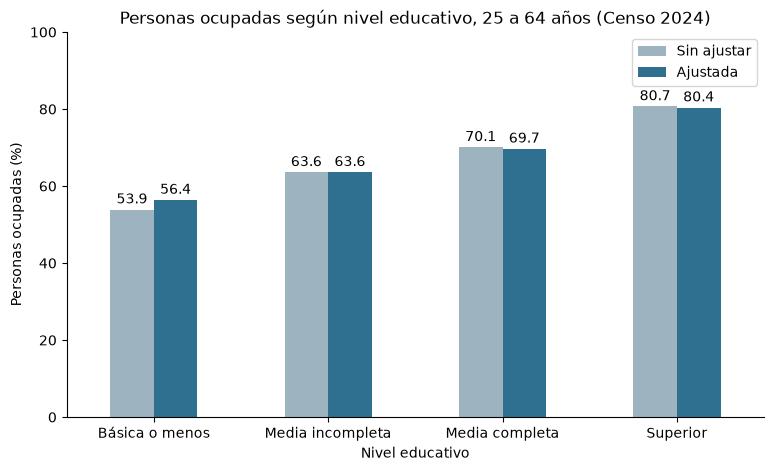

In [18]:
crudo = df_modelo.groupby("nivel_educ")["ocupado"].mean().mul(100).round(1)
ajustado = pd.DataFrame(filas).set_index("nivel_educ")["prob_ocupado_ajustada_%"]

comp = pd.DataFrame({"Sin ajustar": crudo, "Ajustada": ajustado})
comp.index = [n[3:] for n in comp.index]

ax = comp.plot(kind="bar", figsize=(9, 5), color=["#9db4c0", "#2f6f8f"], rot=0)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f", padding=2)

ax.set_title("Personas ocupadas según nivel educativo, 25 a 64 años (Censo 2024)")
ax.set_xlabel("Nivel educativo")
ax.set_ylabel("Personas ocupadas (%)")
ax.set_ylim(0, 100)
ax.legend(title="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

> La ocupación aumenta con el nivel educativo tanto en la muestra sin ajustar (53,9 %, 63,6 %, 70,1 % y 80,7 %) como en las probabilidades ajustadas por edad, sexo, región y nacionalidad (56,4 %, 63,6 %, 69,7 % y 80,4 %). Las diferencias entre ambas series son pequeñas; la mayor se observa en básica o menos (2,5 puntos).

Los controles reducen la brecha entre superior y básica o menos de 26,8 a 24,0 puntos porcentuales. La asociación positiva entre escolaridad y ocupación es robusta a la composición de la población por edad, sexo, región y nacionalidad.

### 🟢 <font color=green> **4.8 Preparación de los datos para vivienda e internet** </font>

Se repite el análisis de la sección 4 para las otras dos dimensiones de la pregunta de investigación: el hacinamiento y el acceso a internet fija. Se definen dos variables a explicar: `hacinado` (1 si la persona vive en una vivienda con hacinamiento medio o crítico, 0 si no) e `internet_fija` (1 si su hogar cuenta con internet fija, 0 si no).

Decisiones metodológicas:

1. **Universo:** a diferencia del modelo de ocupación, no se limita el rango de edad a 25-64 años, porque la jubilación no condiciona el hacinamiento ni el acceso a internet del hogar. Se utilizan las personas de 25 años o más de la base.
2. **Muestra:** una de cada 25 personas, seleccionada de forma reproducible con la misma función hash de 4.1.
3. **Datos faltantes:** los registros sin dato en la variable a explicar quedan vacíos y se excluyen en cada modelo. Se excluyen también los registros sin dato de nacionalidad.

Ambas variables son características del hogar o la vivienda, por lo que las personas del mismo hogar comparten el valor. La muestra incluye pocas personas por hogar, lo que reduce el problema, pero no lo elimina.

In [19]:
df_vida = con.execute("""
    SELECT
        CASE WHEN hacinamiento = '2. Con hacinamiento' THEN 1
             WHEN hacinamiento = '1. Sin hacinamiento' THEN 0 END AS hacinado,
        CASE WHEN acceso_internet = '1. Con internet fija' THEN 1
             WHEN acceso_internet != '4. Sin dato' THEN 0 END AS internet_fija,
        nivel_educ,
        tramo_edad,
        sexo,
        region,
        p27_nacionalidad
    FROM base
    WHERE p27_nacionalidad IN (1, 2, 3)
      AND hash(id_vivienda, id_hogar, id_persona) % 25 = 0
""").df()

print("Filas y columnas:", df_vida.shape)
print("Proporción con hacinamiento:", round(df_vida["hacinado"].mean(), 3))
print("Proporción con internet fija:", round(df_vida["internet_fija"].mean(), 3))
print("Registros sin dato:")
print(df_vida[["hacinado", "internet_fija"]].isna().sum())

Filas y columnas: (496530, 7)
Proporción con hacinamiento: 0.073
Proporción con internet fija: 0.683
Registros sin dato:
hacinado          54
internet_fija    468
dtype: int64


> La muestra contiene **496.530 personas** de 25 años o más. El 7,3 % vive en una vivienda con hacinamiento y el 68,3 % en un hogar con internet fija. Hay 54 registros sin dato de hacinamiento y 468 sin dato de internet fija, que se excluirán en cada modelo.

### 🟢 <font color=green> **4.9 Modelos de hacinamiento**</font>

Se estiman tres modelos de regresión logística para la probabilidad de vivir en una vivienda con hacinamiento, agregando controles de forma sucesiva: ninguno, edad, y edad, sexo, región y nacionalidad. Las categorías de referencia son básica o menos, 25-34 años, hombre, región con código 1 (Tarapacá) y nacionalidad chilena. Se define una función general que recibe la tabla de datos, la variable a explicar y las variables explicativas, y que excluye automáticamente los registros sin dato en la variable a explicar.

#### **4.9.1 Modelo 1: nivel educativo sin controles**

In [20]:
def ajustar_logit(df, objetivo, variables):
    datos = df.dropna(subset=[objetivo])
    X = pd.get_dummies(datos[variables], columns=variables, drop_first=True).astype(int)
    modelo = LogisticRegression(C=np.inf, max_iter=2000)
    modelo.fit(X, datos[objetivo].astype(int))
    return pd.DataFrame({
        "variable": X.columns,
        "odds_ratio": np.exp(modelo.coef_[0]).round(2)
    })

ajustar_logit(df_vida, "hacinado", ["nivel_educ"])

,variable,odds_ratio
0,nivel_educ_2. Media incompleta,1.24
1,nivel_educ_3. Media completa,1.24
2,nivel_educ_4. Superior,0.68


> Sin controles, los odds de vivir en una vivienda con hacinamiento son 1,24 veces mayores en media incompleta y en media completa, y 0,68 veces en el nivel superior (es decir, 32 % menores), respecto de básica o menos.

El resultado es incoherente con lo esperable: los niveles intermedios aparecen con mayor hacinamiento que básica o menos. Una explicación plausible es la edad: el nivel de básica o menos está compuesto principalmente por personas mayores (62 años de edad promedio), que viven en hogares con menor hacinamiento. Esta hipótesis se evalúa en el modelo siguiente, que controla por edad.

#### **4.9.2 Modelo 2: nivel educativo y edad**

Se agrega el tramo de edad como variable de control. Si la edad explica la distorsión observada en el modelo 1, los odds ratios de los niveles intermedios deberían disminuir.

In [21]:
ajustar_logit(df_vida, "hacinado", ["nivel_educ", "tramo_edad"])

,variable,odds_ratio
0,nivel_educ_2. Media incompleta,0.91
1,nivel_educ_3. Media completa,0.69
2,nivel_educ_4. Superior,0.32
3,tramo_edad_35-44,0.71
4,tramo_edad_45-54,0.36
5,tramo_edad_55-64,0.26
6,tramo_edad_65-74,0.19
7,tramo_edad_75-84,0.15
8,tramo_edad_85+,0.13


> Al controlar por tramo de edad, los odds de vivir con hacinamiento disminuyen con el nivel educativo respecto de básica o menos: 0,91 en media incompleta, 0,69 en media completa y 0,32 en el nivel superior (frente a 1,24, 1,24 y 0,68 en el modelo sin controles). Respecto del tramo de 25-34 años, los odds de hacinamiento caen en cada tramo de edad: 0,71 a los 35-44 años, 0,36 a los 45-54, 0,26 a los 55-64, 0,19 a los 65-74, 0,15 a los 75-84 y 0,13 en el grupo de 85 años o más.

Al comparar personas de la misma edad, el hacinamiento disminuye con la escolaridad, y los resultados del modelo 1 se invierten: la aparente mayor frecuencia de hacinamiento en los niveles intermedios se debía a que el nivel de referencia (básica o menos) está compuesto por personas mayores. Se trata de una paradoja de Simpson: la tendencia del conjunto no coincide con la de los grupos de edad. La edad tiene una asociación con el hacinamiento más fuerte que la del nivel educativo.

#### **4.9.3 Modelo 3: nivel educativo con todos los controles**

Se incorporan sexo, región y nacionalidad como controles, además del tramo de edad. Los coeficientes de región se incluyen como ajuste y no se interpretan individualmente.

In [22]:
ajustar_logit(df_vida, "hacinado", ["nivel_educ", "tramo_edad", "sexo", "region", "p27_nacionalidad"])

,variable,odds_ratio
0,nivel_educ_2. Media incompleta,0.87
1,nivel_educ_3. Media completa,0.66
2,nivel_educ_4. Superior,0.31
3,tramo_edad_35-44,0.72
4,tramo_edad_45-54,0.40
5,tramo_edad_55-64,0.31
6,tramo_edad_65-74,0.24
7,tramo_edad_75-84,0.18
8,tramo_edad_85+,0.15
9,sexo_2,1.09


> Al controlar simultáneamente por edad, sexo, región y nacionalidad, los odds de vivir con hacinamiento disminuyen con el nivel educativo respecto de básica o menos: 0,87 en media incompleta, 0,66 en media completa y 0,31 en el nivel superior (0,91, 0,69 y 0,32 en el modelo que solo controla por edad). Los odds también disminuyen con la edad (0,15 en el grupo de 85 años o más frente al de 25-34). El odds ratio de las mujeres respecto de los hombres es 1,09; el de las personas de otra nacionalidad respecto de las chilenas es 2,92 (1,15 en doble nacionalidad). Los odds ratios por región varían entre 0,74 y 1,12 respecto de Tarapacá.

La asociación entre nivel educativo y hacinamiento es robusta al conjunto de controles: los resultados casi no cambian respecto del modelo que solo controla por edad, que fue el control decisivo. La asociación con el sexo es prácticamente nula, lo que es coherente con que el hacinamiento sea una característica del hogar. La nacionalidad se asocia fuertemente con el hacinamiento, con una magnitud comparable a la del nivel educativo superior.

Los resultados describen asociaciones y no permiten identificar las causas de las diferencias observadas, en particular las asociadas a la nacionalidad. El modelo no incluye intervalos de confianza, y las personas del mismo hogar comparten el valor de la variable a explicar.

#### **4.9.4 Probabilidades ajustadas de hacinamiento**

Para expresar los resultados del modelo 3 en porcentajes, se calcula para cada nivel educativo la probabilidad promedio de vivir con hacinamiento que resultaría si todas las personas de la muestra tuvieran ese nivel, manteniendo su edad, sexo, región y nacionalidad. Se incluye también el porcentaje observado sin ajustar, para evaluar el efecto de los controles. La lógica es la misma de 4.6 y se encapsula en una función reutilizable.

In [23]:
def prob_ajustada(df, objetivo, variables):
    datos = df.dropna(subset=[objetivo])
    X = pd.get_dummies(datos[variables], columns=variables, drop_first=True).astype(int)
    modelo = LogisticRegression(C=np.inf, max_iter=2000).fit(X, datos[objetivo].astype(int))

    columnas_educ = [c for c in X.columns if c.startswith("nivel_educ_")]
    niveles = sorted(datos["nivel_educ"].unique())
    sin_ajustar = datos.groupby("nivel_educ")[objetivo].mean().mul(100)

    filas = []
    for nivel in niveles:
        Xc = X.copy()
        Xc[columnas_educ] = 0
        if nivel != niveles[0]:
            Xc[f"nivel_educ_{nivel}"] = 1
        filas.append({
            "nivel_educ": nivel,
            "sin_ajustar_%": round(sin_ajustar[nivel], 1),
            "ajustada_%": round(100 * modelo.predict_proba(Xc)[:, 1].mean(), 1)
        })
    return pd.DataFrame(filas)

prob_hacinamiento = prob_ajustada(
    df_vida, "hacinado", ["nivel_educ", "tramo_edad", "sexo", "region", "p27_nacionalidad"]
)
prob_hacinamiento

,nivel_educ,sin_ajustar_%,ajustada_%
0,1. Básica o menos,7.6,12.2
1,2. Media incompleta,9.2,10.9
2,3. Media completa,9.2,8.6
3,4. Superior,5.3,4.4


> Sin ajustar, el porcentaje de personas que viven con hacinamiento es de 7,6 % en básica o menos, 9,2 % en media incompleta, 9,2 % en media completa y 5,3 % en el nivel superior. Ajustado por edad, sexo, región y nacionalidad, es de 12,2 %, 10,9 %, 8,6 % y 4,4 %, respectivamente.

Sin controles, el nivel de básica o menos aparece con menos hacinamiento que los niveles intermedios y la brecha con el nivel superior es de 2,3 puntos porcentuales; al comparar personas por lo demás equivalentes, el hacinamiento disminuye de forma continua con el nivel educativo y la brecha asciende a 7,8 puntos. La edad ocultaba la asociación (paradoja de Simpson). Los resultados describen una asociación y no un efecto causal.

### <font color=green> 🟢 **4.10 Modelos de acceso a internet fija** </font>

Se repite la estructura de 4.9 para la probabilidad de vivir en un hogar con internet fija: tres modelos de regresión logística con controles sucesivos (ninguno, edad, y edad, sexo, región y nacionalidad). Las categorías de referencia son las mismas.

#### **4.10.1 Modelo 1: nivel educativo sin controles**

In [24]:
ajustar_logit(df_vida, "internet_fija", ["nivel_educ"])

,variable,odds_ratio
0,nivel_educ_2. Media incompleta,1.94
1,nivel_educ_3. Media completa,2.55
2,nivel_educ_4. Superior,5.86


> Sin controles, los odds de vivir en un hogar con internet fija son 1,94 veces mayores en media incompleta, 2,55 veces en media completa y 5,86 veces en el nivel superior, respecto de básica o menos. En términos de probabilidad, el porcentaje de personas con internet fija en el hogar pasa de 45 % (básica o menos) a 83 % (superior).

La asociación es positiva y creciente en todos los niveles, sin las inconsistencias observadas en el modelo de hacinamiento. Estos resultados coinciden con los de la tabla 3.5.

#### **4.10.2 Modelo 2: nivel educativo y edad**

Se agrega el tramo de edad como variable de control. En 3.5 la brecha entre niveles educativos era similar dentro de cada tramo de edad y en el conjunto, por lo que se espera que los odds ratios del nivel educativo varíen poco.

In [25]:
ajustar_logit(df_vida, "internet_fija", ["nivel_educ", "tramo_edad"])

,variable,odds_ratio
0,nivel_educ_2. Media incompleta,1.92
1,nivel_educ_3. Media completa,2.53
2,nivel_educ_4. Superior,5.91
3,tramo_edad_35-44,1.17
4,tramo_edad_45-54,1.23
5,tramo_edad_55-64,1.22
6,tramo_edad_65-74,1.13
7,tramo_edad_75-84,0.95
8,tramo_edad_85+,1.02


> Al controlar por tramo de edad, los odds de vivir en un hogar con internet fija se mantienen prácticamente iguales a los del modelo sin controles: 1,92 en media incompleta, 2,53 en media completa y 5,91 en el nivel superior (1,94, 2,55 y 5,86 sin controlar), respecto de básica o menos. Respecto del tramo de 25-34 años, los odds ratios de edad están entre 0,95 y 1,23, con valores cercanos a 1 en los tramos de 75 años o más.

La edad explica una parte mínima de la asociación entre nivel educativo y acceso a internet fija, a diferencia de lo observado en ocupación (donde la reduce levemente) y en hacinamiento (donde la invierte). Esto es coherente con lo observado en 3.5, donde la brecha era similar en todos los tramos de edad.

#### **4.10.3 Modelo 3: nivel educativo con todos los controles**

Se incorporan sexo, región y nacionalidad como controles, además del tramo de edad. Dado que el acceso a internet fija es una característica del hogar y de su localización, se espera que el sexo tenga una asociación débil y que la región tenga más peso que en los modelos anteriores.

In [26]:
ajustar_logit(df_vida, "internet_fija", ["nivel_educ", "tramo_edad", "sexo", "region", "p27_nacionalidad"])

,variable,odds_ratio
0,nivel_educ_2. Media incompleta,1.75
1,nivel_educ_3. Media completa,2.36
2,nivel_educ_4. Superior,5.19
3,tramo_edad_35-44,1.17
4,tramo_edad_45-54,1.21
5,tramo_edad_55-64,1.16
6,tramo_edad_65-74,1.04
7,tramo_edad_75-84,0.86
8,tramo_edad_85+,0.89
9,sexo_2,1.14


> Al controlar simultáneamente por edad, sexo, región y nacionalidad, los odds de vivir en un hogar con internet fija aumentan con el nivel educativo respecto de básica o menos: 1,75 en media incompleta, 2,36 en media completa y 5,19 en el nivel superior (1,92, 2,53 y 5,91 en el modelo que solo controla por edad). El odds ratio de las mujeres respecto de los hombres es 1,14; el de las personas de otra nacionalidad respecto de las chilenas es 0,60 (1,14 en doble nacionalidad). Los odds ratios por región, respecto de Tarapacá, varían entre 0,33 (La Araucanía) y 1,36 (Antofagasta); los de edad, entre 0,86 y 1,21.

La asociación entre nivel educativo y acceso a internet fija es la más fuerte de las tres dimensiones y se mantiene con todos los controles, aunque se reduce cerca de un 12 % al incorporar la región, lo que indica que parte de la asociación observada se relaciona con la distribución geográfica del acceso. A diferencia de los modelos de ocupación y hacinamiento, la región tiene aquí una asociación de magnitud relevante, mayor que la de la edad.

Los resultados describen asociaciones y no efectos causales. Los odds ratios de región se miden respecto de una región de referencia y no deben leerse como niveles absolutos. El acceso a internet es una característica del hogar y las personas del mismo hogar comparten el valor.

#### **4.10.4 Probabilidades ajustadas de acceso a internet fija**

Se calcula, para cada nivel educativo, la probabilidad promedio de vivir en un hogar con internet fija que resultaría si todas las personas de la muestra tuvieran ese nivel, manteniendo su edad, sexo, región y nacionalidad. Se incluye el porcentaje observado sin ajustar para evaluar el efecto de los controles.

In [27]:
prob_internet = prob_ajustada(
    df_vida, "internet_fija", ["nivel_educ", "tramo_edad", "sexo", "region", "p27_nacionalidad"]
)
prob_internet

,nivel_educ,sin_ajustar_%,ajustada_%
0,1. Básica o menos,45.1,48.3
1,2. Media incompleta,61.5,61.3
2,3. Media completa,67.7,67.8
3,4. Superior,82.8,81.7


> Sin ajustar, el porcentaje de personas que viven en un hogar con internet fija es de 45,1 % en básica o menos, 61,5 % en media incompleta, 67,7 % en media completa y 82,8 % en el nivel superior. Ajustado por edad, sexo, región y nacionalidad, es de 48,3 %, 61,3 %, 67,8 % y 81,7 %, respectivamente.

Al ajustar, los niveles intermedios prácticamente no cambian y la brecha entre superior y básica o menos se reduce de 37,7 a 33,4 puntos porcentuales (cerca de un 11 %), lo que refleja principalmente la distribución geográfica del acceso. La brecha sigue siendo la mayor de las tres dimensiones analizadas. Los resultados describen una asociación y no un efecto causal, y el acceso corresponde al hogar y no al uso individual.

### 🟢 <font color=green> **4.11 Comparación de las tres dimensiones** </font>

Se resumen en una sola tabla los resultados de los modelos de ocupación, hacinamiento e internet fija: la probabilidad ajustada en el nivel educativo más bajo (básica o menos) y en el más alto (superior), y la brecha entre ambos, en puntos porcentuales, antes y después de ajustar por los controles. La brecha se calcula como superior menos básica o menos: un valor positivo indica un porcentaje mayor en el nivel superior y uno negativo, menor.

In [28]:
niveles_etiqueta = ["1. Básica o menos", "2. Media incompleta", "3. Media completa", "4. Superior"]

tablas = {
    "Ocupación (25 a 64 años)": comp.rename(columns={"Sin ajustar": "sin_ajustar_%", "Ajustada": "ajustada_%"})
                                    .set_axis(niveles_etiqueta, axis=0),
    "Hacinamiento (25 años o más)": prob_hacinamiento.set_index("nivel_educ"),
    "Internet fija (25 años o más)": prob_internet.set_index("nivel_educ"),
}

filas = []
for nombre, t in tablas.items():
    bajo, alto = "1. Básica o menos", "4. Superior"
    filas.append({
        "Dimensión": nombre,
        "Básica o menos, ajustada (%)": t.loc[bajo, "ajustada_%"],
        "Superior, ajustada (%)": t.loc[alto, "ajustada_%"],
        "Brecha sin ajustar (pp)": round(t.loc[alto, "sin_ajustar_%"] - t.loc[bajo, "sin_ajustar_%"], 1),
        "Brecha ajustada (pp)": round(t.loc[alto, "ajustada_%"] - t.loc[bajo, "ajustada_%"], 1),
    })

pd.DataFrame(filas)

,Dimensión,"Básica o menos, ajustada (%)","Superior, ajustada (%)",Brecha sin ajustar (pp),Brecha ajustada (pp)
0,Ocupación (25 a 64 años),56.4,80.4,26.8,24.0
1,Hacinamiento (25 años o más),12.2,4.4,-2.3,-7.8
2,Internet fija (25 años o más),48.3,81.7,37.7,33.4


> Con todos los controles, la brecha entre el nivel superior y básica o menos es de 24,0 puntos porcentuales en ocupación (80,4 % y 56,4 %), de −7,8 en hacinamiento (4,4 % y 12,2 %) y de 33,4 en acceso a internet fija (81,7 % y 48,3 %). Sin ajustar, las brechas eran de 26,8, −2,3 y 37,7 puntos, respectivamente.

En las tres dimensiones, un mayor nivel educativo se asocia con mejores condiciones (más ocupación, menos hacinamiento y más acceso a internet) una vez controladas la edad, el sexo, la región y la nacionalidad. Los controles reducen cerca de un 10 % la brecha de ocupación y de internet, y más que la triplican en hacinamiento, donde la edad ocultaba la asociación. La dimensión con la asociación más fuerte depende de la medida: en puntos porcentuales es el acceso a internet; en términos relativos, el hacinamiento; y en odds ratios (3,49 para ocupación, 0,31 para hacinamiento y 5,19 para internet), el acceso a internet.

>Las dimensiones no son directamente comparables, porque parten de niveles distintos y el modelo de ocupación usa personas de 25 a 64 años mientras que los otros usan personas de 25 años o más. Los resultados describen asociaciones y no efectos causales.

### 🟢 <font color=green> **4.12 Resumen de la sección** </font>

Se estimaron regresiones logísticas para tres condiciones de vida, incorporando controles de forma sucesiva (edad; luego sexo, región y nacionalidad). La tabla muestra el odds ratio del nivel educativo superior respecto de básica o menos:

| Dimensión | Modelo 1: sin controles | Modelo 2: + edad | Modelo 3: + sexo, región y nacionalidad |
|---|---|---|---|
| Ocupación (25-64 años) | 3,57 | 3,17 | 3,49 |
| Hacinamiento (25 años o más) | 0,68 | 0,32 | 0,31 |
| Internet fija (25 años o más) | 5,86 | 5,91 | 5,19 |

- **Ocupación:** la asociación con la escolaridad es robusta. La edad la reduce levemente, y el sexo (odds ratio de 0,32 para las mujeres) la recupera en parte. Con todos los controles, la probabilidad de estar ocupado es de 56,4 % en básica o menos y de 80,4 % en superior.
- **Hacinamiento:** sin controlar, los niveles intermedios aparecían con más hacinamiento que básica o menos (paradoja de Simpson causada por la edad). Al controlar la edad, el orden se corrige, y la asociación se mantiene con los demás controles: 12,2 % en básica o menos y 4,4 % en superior. Las personas de otra nacionalidad tienen odds de hacinamiento cerca de tres veces mayores (2,92).
- **Internet fija:** es la asociación más fuerte en odds ratios. La edad no la modifica, pero la región la reduce cerca de un 12 %: 48,3 % en básica o menos y 81,7 % en superior.
- **Aprendizaje común:** el efecto de un control no se puede anticipar. La edad redujo levemente la asociación en ocupación, la invirtió en hacinamiento y no la alteró en internet.

> Los resultados describen asociaciones y no efectos causales; los modelos no incluyen intervalos de confianza; las variables de hogar y vivienda se atribuyen a todos sus integrantes; el modelo de ocupación usa personas de 25 a 64 años y los otros dos, de 25 años o más; y la zona (urbana o rural) no está incluida como control.

## 🔵 <font color=blue> **5. Conclusiones** </font>

### 🟢 <font color=green> **5.1 Respuesta a la pregunta de investigación** </font>

**¿Cómo se asocia el nivel de escolaridad con las condiciones de vida, una vez controlados factores como la edad y el sexo?**

En el Censo 2024, entre las 12,4 millones de personas de 25 años o más que viven en viviendas particulares, un mayor nivel educativo se asocia con mejores condiciones de vida en las tres dimensiones estudiadas: más ocupación, menos hacinamiento y más acceso a internet fija. La asociación se mantiene al controlar por edad, sexo, región y nacionalidad.

| Dimensión | Básica o menos | Superior | Brecha ajustada |
|---|---|---|---|
| Ocupación (25 a 64 años) | 56,4 % | 80,4 % | +24,0 puntos |
| Hacinamiento | 12,2 % | 4,4 % | −7,8 puntos |
| Acceso a internet fija en el hogar | 48,3 % | 81,7 % | +33,4 puntos |

*Porcentajes ajustados por edad, sexo, región y nacionalidad (secciones 4.7, 4.9.4 y 4.10.4).*

#### Hallazgos principales

1. **La asociación es robusta.** Sobrevive a los controles en las tres dimensiones. En términos de odds ratio, el nivel superior frente a básica o menos es de 3,49 en ocupación, 0,31 en hacinamiento y 5,19 en acceso a internet fija (4.12).
2. **La edad cumple papeles distintos según la dimensión.** En ocupación reduce levemente la asociación, en hacinamiento la oculta (sin controlarla, los niveles intermedios parecían tener *más* hacinamiento: una paradoja de Simpson), y en internet casi no la modifica. Por eso los controles deben estimarse y no suponerse (3.4 y 4.9).
3. **La escolaridad depende mucho de la generación.** El promedio baja de unos 14 años en el tramo de 25-34 años a cerca de 7 en el de 85 o más. Las mujeres superan a los hombres en las generaciones jóvenes y los hombres a las mujeres en las mayores, con un cruce alrededor de los 52-53 años (2.3 y 2.5).
4. **La región importa en el acceso a internet,** y poco en ocupación y hacinamiento. Al incorporarla, la asociación de la escolaridad con internet se reduce cerca de un 12 % (4.10.3).
5. **Otros factores también se asocian con las condiciones de vida.** Las mujeres tienen odds de estar ocupadas cerca de un tercio de los de los hombres con igual escolaridad, edad, región y nacionalidad (0,32). Las personas de otra nacionalidad tienen odds de hacinamiento casi tres veces mayores (2,92) y odds de acceso a internet fija menores (0,60) (4.5, 4.9.3 y 4.10.3).

> Podemos decir, entonces, que hay una asociación consistente entre el nivel educativo y las condiciones de vida de las personas de 25 años o más que viven en viviendas particulares en Chile: aparece en las tres dimensiones analizadas y se mantiene al controlar por edad, sexo, región y nacionalidad, aunque su magnitud varía según la dimensión.

>**Importante:** estos resultados describen asociaciones y no demuestran que la escolaridad cause las diferencias observadas.


### 🟢 <font color=green> **5.2 Limitaciones** </font>

1. **Asociación, no causalidad.** Los resultados no permiten afirmar que la escolaridad cause las diferencias observadas. No se incluyeron otros factores que podrían influir (por ejemplo, ingresos u otras características del hogar), y el censo es una fotografía de un único momento: no permite separar el efecto de la edad del efecto de la generación.

2. **Universo acotado.** El análisis cubre a las personas de 25 años o más que viven en viviendas particulares (67,2 % de la población censada). No aplica a menores de 25 años, ni a viviendas colectivas o personas en situación de calle. El modelo de ocupación se limita además a personas de 25 a 64 años.

3. **Variables del hogar atribuidas a las personas.** El hacinamiento y el acceso a internet son características del hogar o la vivienda, y todos sus integrantes comparten el valor. Esto implica que las observaciones no son independientes, y que el acceso a internet del hogar no equivale al uso individual.

4. **Decisiones de agrupación.** La edad se agrupó en tramos de diez años (el último, "85 o más", es un tope del INE) y los años de escolaridad en cuatro niveles; el nivel superior reúne trayectorias muy distintas (técnicas, universitarias y posgrados).

5. **Límites de los modelos.** Se estimaron sobre una muestra del 4 %, sin intervalos de confianza, y no se exploraron interacciones (por ejemplo, si el efecto de la escolaridad difiere entre hombres y mujeres). Los coeficientes de región se usaron solo como ajuste.

6. **Variables preparadas y no analizadas.** Se construyeron la tenencia de la vivienda, la ocupación agrupada y la tenencia de computador, pero no se incorporaron al análisis final.

### 🟢 <font color=green> **5.3 Próximos pasos** </font>

- Incorporar la **zona (urbana o rural)** como variable de control, disponible en las tablas originales.
- Analizar las variables ya preparadas: **tenencia de la vivienda, tipo de ocupación y computador en el hogar**.
- Estimar intervalos de confianza (por ejemplo, con `statsmodels`) y explorar interacciones entre escolaridad y sexo o región.
- Ampliar el análisis a **nivel comuna**, cruzando los datos del censo con resultados electorales del Servel, considerando la falacia ecológica: una asociación entre comunas no implica la misma asociación entre personas.